<a href="https://colab.research.google.com/github/ggalarza1/AI_Finance/blob/main/NormativeFinance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

In [2]:
S0 = 10
B0 = 10

In [3]:
S1 = np.array((20,5))
B1 = np.array((11,11))

In [4]:
M0 = np.array((S0, B0))
M0

array([10, 10])

In [5]:
M1 = np.array((S1, B1)).T
M1

array([[20, 11],
       [ 5, 11]])

In [6]:
K = 14.5

In [7]:
C1 = np.maximum (S1 - K, 0)
C1

array([5.5, 0. ])

In [8]:
phi = np.linalg.solve(M1, C1)
phi

array([ 0.36666667, -0.16666667])

In [9]:
np.allclose(C1, np.dot(M1, phi))

True

In [10]:
C0 = np.dot(M0, phi)
C0

np.float64(2.0)

In [11]:
def u(x):
  return np.sqrt(x)

In [12]:
phi_A = np.array((0.75, 0.25))
phi_D = np.array((0.25, 0.75))

In [13]:
np.dot(M0, phi_A) == np.dot(M0, phi_D)

np.True_

In [14]:
A1 = np.dot(M1, phi_A)
A1

array([17.75,  6.5 ])

In [15]:
D1 = np.dot(M1, phi_D)
D1

array([13.25,  9.5 ])

In [16]:
P = np.array((0.5, 0.5))
P

array([0.5, 0.5])

In [17]:
def EUT(x):
    return np.dot(P, u(x))

In [18]:
EUT(A1)

np.float64(3.381292321692286)

In [19]:
EUT(D1)

np.float64(3.3611309730623735)

In [20]:
from scipy.optimize import minimize

In [21]:
w = 10

In [22]:
cons = {'type': 'eq', 'fun': lambda phi: np.dot(M0, phi) - w}

In [23]:
def EUT_(phi):
  x = np.dot(M1, phi)
  return EUT(x)

In [24]:
opt = minimize(lambda phi: -EUT_(phi),
               x0=phi_A,
               constraints=cons)

In [25]:
opt

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -3.385015999493397
           x: [ 6.112e-01  3.888e-01]
         nit: 4
         jac: [-1.692e+00 -1.693e+00]
        nfev: 12
        njev: 4
 multipliers: [-1.693e-01]

In [26]:
EUT_(opt['x'])

np.float64(3.385015999493397)

In [27]:
rS= S1 / S0 - 1
rS

array([ 1. , -0.5])

In [28]:
rB = B1 / B0 - 1
rB

array([0.1, 0.1])

In [29]:
def mu(rX):
  return np.dot(P, rX)

In [30]:
mu(rS)

np.float64(0.25)

In [31]:
mu(rS)

np.float64(0.25)

In [32]:
mu(rB)

np.float64(0.10000000000000009)

In [33]:
rM = M1 / M0 - 1
rM

array([[ 1. ,  0.1],
       [-0.5,  0.1]])

In [34]:
mu(rM)

array([0.25, 0.1 ])

In [35]:
def var(rX):
  return ((rX - mu(rX))** 2).mean()

In [36]:
var(rS)

np.float64(0.5625)

In [37]:
var(rB)

np.float64(0.0)

In [38]:
def sigma(rX):
  return np.sqrt(var(rX))

In [39]:
sigma(rS)

np.float64(0.75)

In [40]:
sigma(rB)

np.float64(0.0)

In [41]:
np.cov(rM.T, aweights=P, ddof=0)

array([[0.5625, 0.    ],
       [0.    , 0.    ]])

In [42]:
phi = np.array((0.5, 0.5))

In [43]:
def mu_phi(phi):
  return np.dot(phi, mu(rM))

In [44]:
mu_phi(phi)

np.float64(0.17500000000000004)

In [45]:
def var_phi(phi):
  cv = np.cov(rM.T, aweights=P, ddof=0)
  return np.dot(phi, np.dot(cv, phi))

In [46]:
var_phi(phi)

np.float64(0.140625)

In [47]:
def sigma_phi(phi):
  return var_phi(phi)**0.5

In [48]:
sigma_phi(phi)

np.float64(0.375)

In [49]:
from pylab import plt, mpl
plt.style.use('seaborn-v0_8')
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

In [50]:
phi_mcs = np.random.random((2,200))

In [51]:
phi_mcs = (phi_mcs / phi_mcs.sum(axis=0)).T

In [52]:
mcs = np.array([(sigma_phi(phi), mu_phi(phi))
              for phi in phi_mcs])

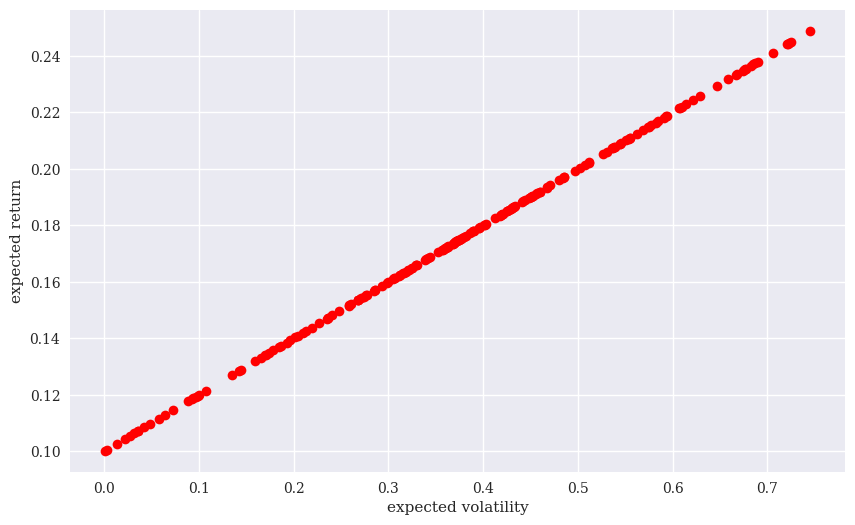

In [53]:
plt.figure(figsize=(10,6))
plt.plot(mcs[:,0], mcs[:,1], 'ro')
plt.xlabel('expected volatility')
plt.ylabel('expected return');
plt.grid(True)
plt.show()

In [54]:
P = np.ones(3) / 3
P

array([0.33333333, 0.33333333, 0.33333333])

In [55]:
S1 = np.array((20, 10, 5))

In [56]:
T0 = 10
T1 = np.array((1, 12, 13))

In [57]:
M0 = np.array((S0, T0))
M0

array([10, 10])

In [58]:
M1 = np.array((S1, T1)).T
M1

array([[20,  1],
       [10, 12],
       [ 5, 13]])

In [59]:
rM = M1 / M0 - 1
rM

array([[ 1. , -0.9],
       [ 0. ,  0.2],
       [-0.5,  0.3]])

In [60]:
mcs = np.array([(sigma_phi(phi), mu_phi(phi))
              for phi in phi_mcs])

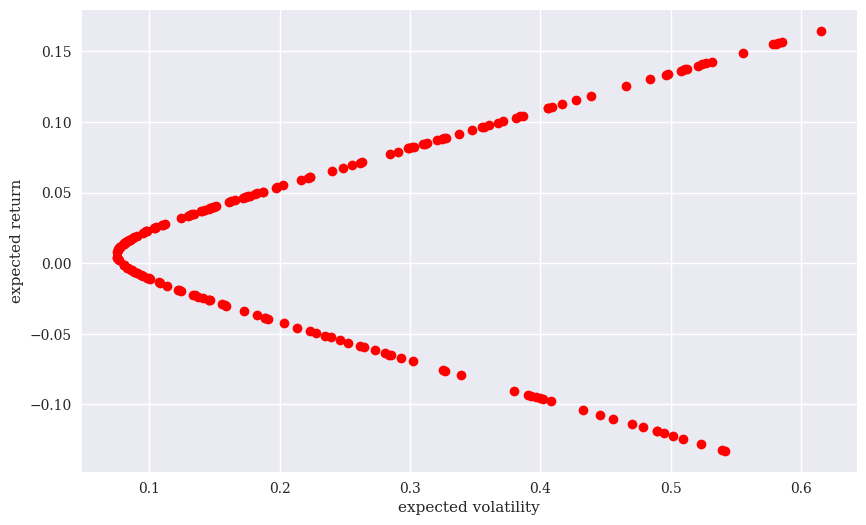

In [61]:
plt.figure(figsize=(10,6))
plt.plot(mcs[:,0], mcs[:,1], 'ro')
plt.xlabel('expected volatility')
plt.ylabel('expected return');
plt.grid(True)
plt.show()

In [62]:
cons = {'type': 'eq', 'fun': lambda phi: np.sum(phi) - 1}

In [63]:
bnds = ((0,1), (0,1))

In [64]:
min_var = minimize(sigma_phi, (0.5, 0.5),
                   constraints=cons, bounds=bnds)

In [65]:
min_var

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.07481322946903253
           x: [ 4.651e-01  5.349e-01]
         nit: 4
         jac: [ 7.427e-02  7.529e-02]
        nfev: 13
        njev: 4
 multipliers: [ 7.481e-02]

In [66]:
def sharpe(phi):
    return mu_phi(phi) / sigma_phi(phi)

In [67]:
max_sharpe = minimize(lambda phi: -sharpe(phi),
                      (0.5, 0.5),
                      constraints=cons, bounds=bnds)

In [68]:
max_sharpe

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -0.27216540990278126
           x: [ 6.673e-01  3.327e-01]
         nit: 9
         jac: [ 1.205e-04 -2.417e-04]
        nfev: 29
        njev: 9
 multipliers: [ 1.396e-06]

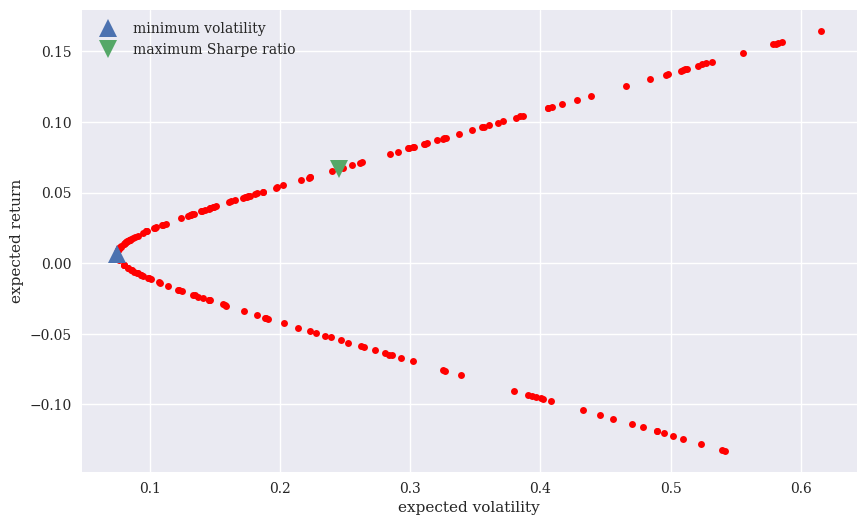

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

In [70]:
plt.figure(figsize=(10,6))
plt.plot(mcs[:,0], mcs[:,1], 'ro', ms=5)
plt.plot(sigma_phi(min_var['x']),
         mu_phi(min_var['x']), '^', ms=12.5, label= 'minimum volatility')
plt.plot(sigma_phi(max_sharpe['x']),
         mu_phi(max_sharpe['x']), 'v', ms=12.5, label='maximum Sharpe ratio')
plt.xlabel('expected volatility')
plt.ylabel('expected return');
plt.grid(True)
plt.legend()
plt.show()
plt

In [71]:
cons =[{'type': 'eq', 'fun': lambda phi: np.sum(phi) - 1},
        {'type': 'eq', 'fun': lambda phi: mu_phi(phi)- target}]

In [72]:
bnds = ((0,1) , (0,1))

In [73]:
targets = np.linspace(mu_phi(min_var['x']), 0.16)

In [75]:
frontier = []
for target in targets:
    phi_eff = minimize(sigma_phi, (0.5, 0.5),
                       constraints=cons, bounds=bnds)['x']
    frontier.append((sigma_phi(phi_eff), mu_phi(phi_eff)))

frontier = np.array(frontier)

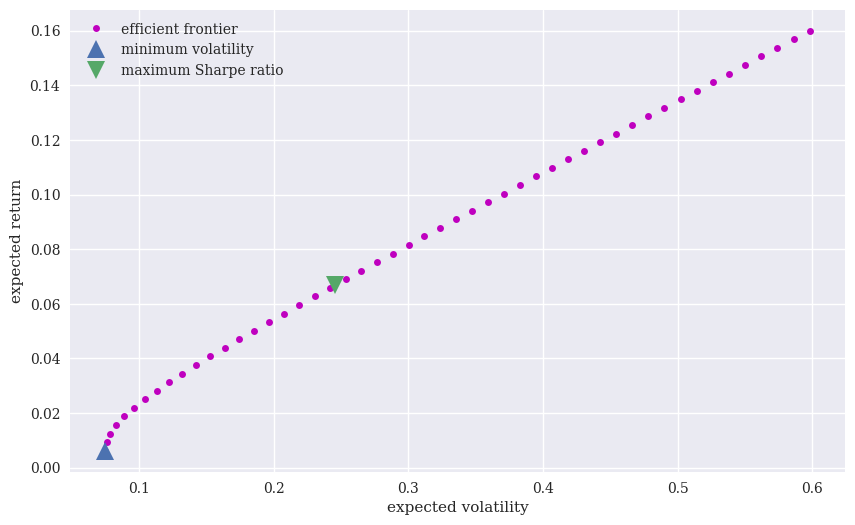

In [76]:
plt.figure(figsize=(10,6))
plt.plot(frontier[:,0], frontier[:,1], 'mo', ms=5,
         label='efficient frontier')
plt.plot(sigma_phi(min_var['x']),
         mu_phi(min_var['x']), '^', ms=12.5, label= 'minimum volatility')
plt.plot(sigma_phi(max_sharpe['x']),
         mu_phi(max_sharpe['x']), 'v', ms=12.5, label='maximum Sharpe ratio')
plt.xlabel('expected volatility')
plt.ylabel('expected return');
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(10,6))
plt.plot((0, 0.3), (0.01, 0.22), label='capital market line')
plt.plot(0, 0.01, 'o', ms=9, label='risk-less asset')